In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
df['Survived'].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

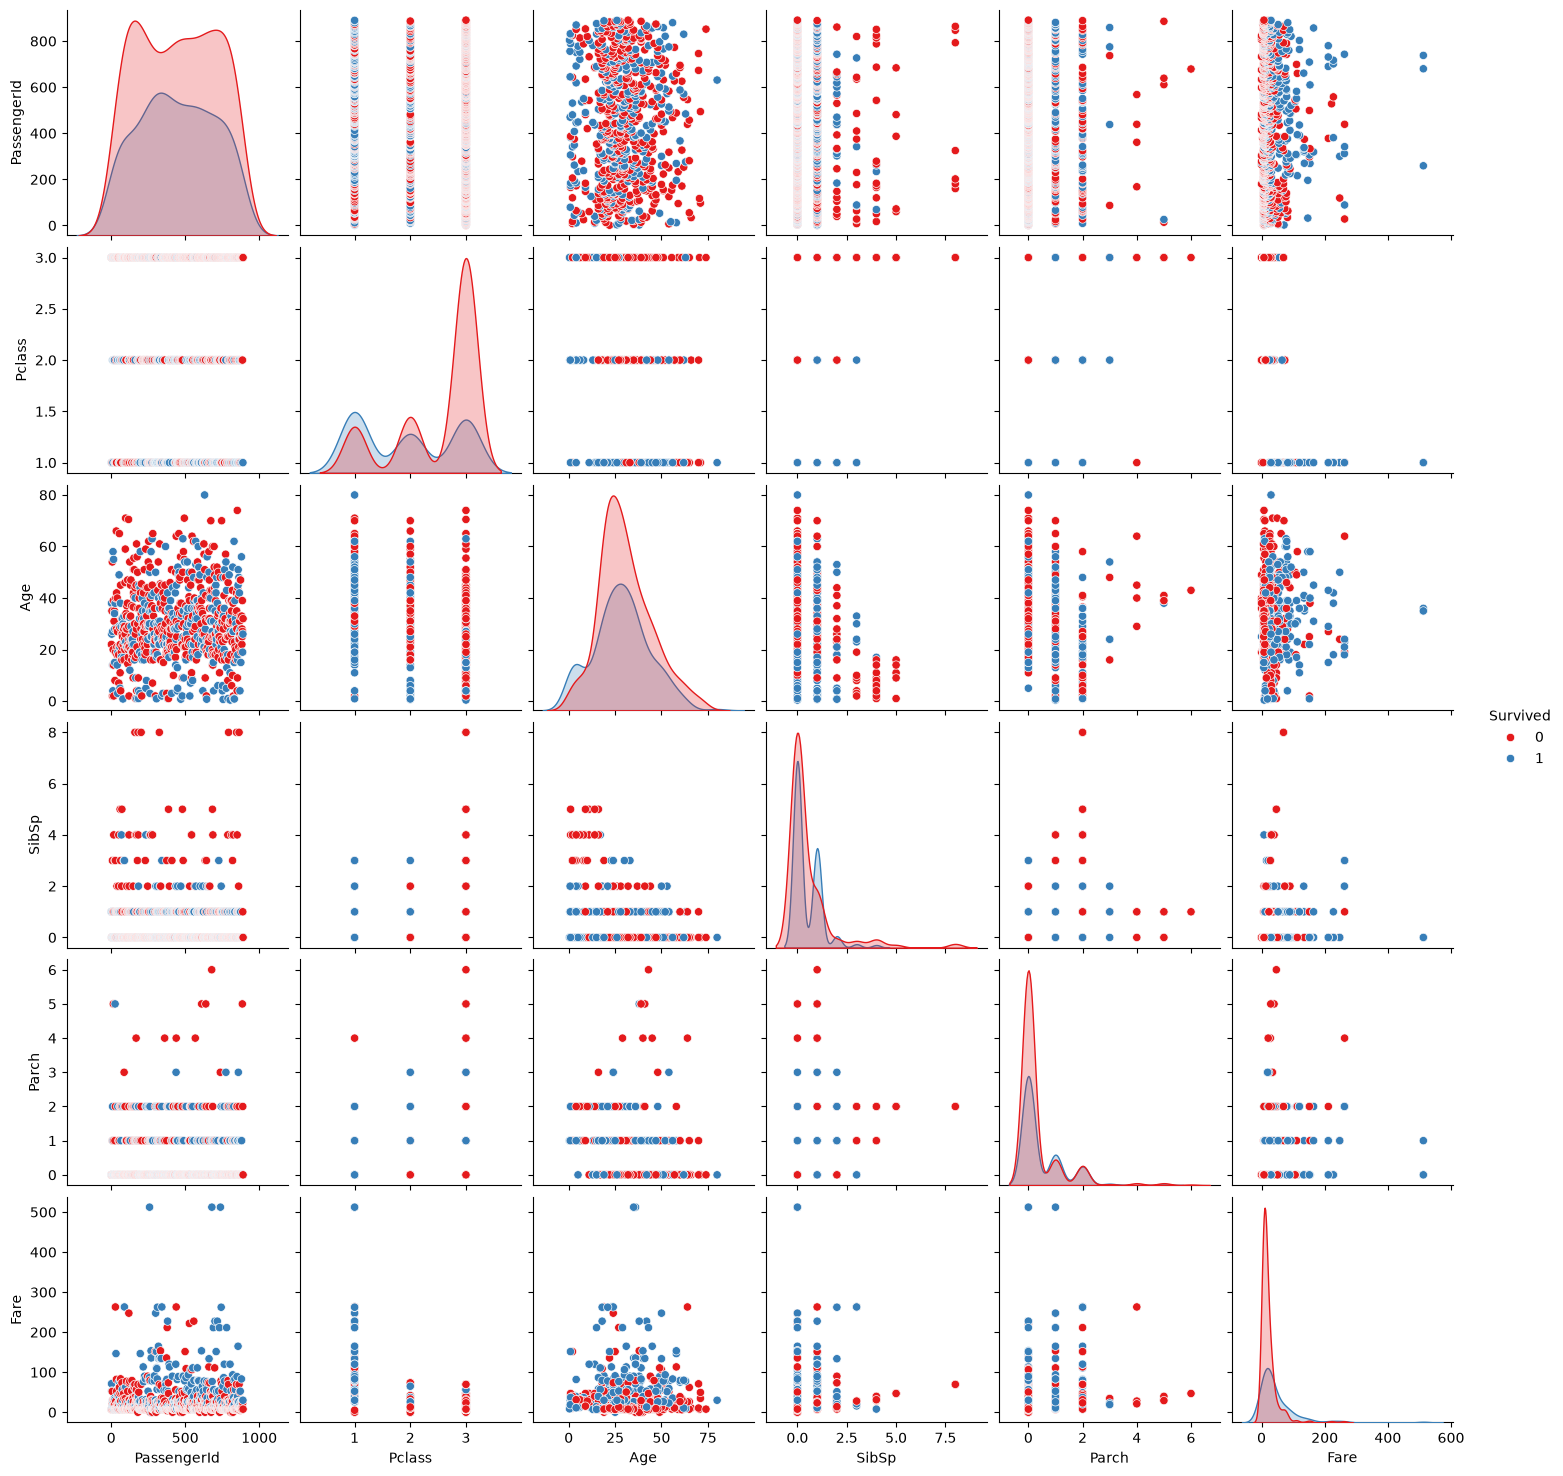

In [8]:
sns.pairplot(df, hue='Survived', palette='Set1', diag_kind='kde')

In [9]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: >

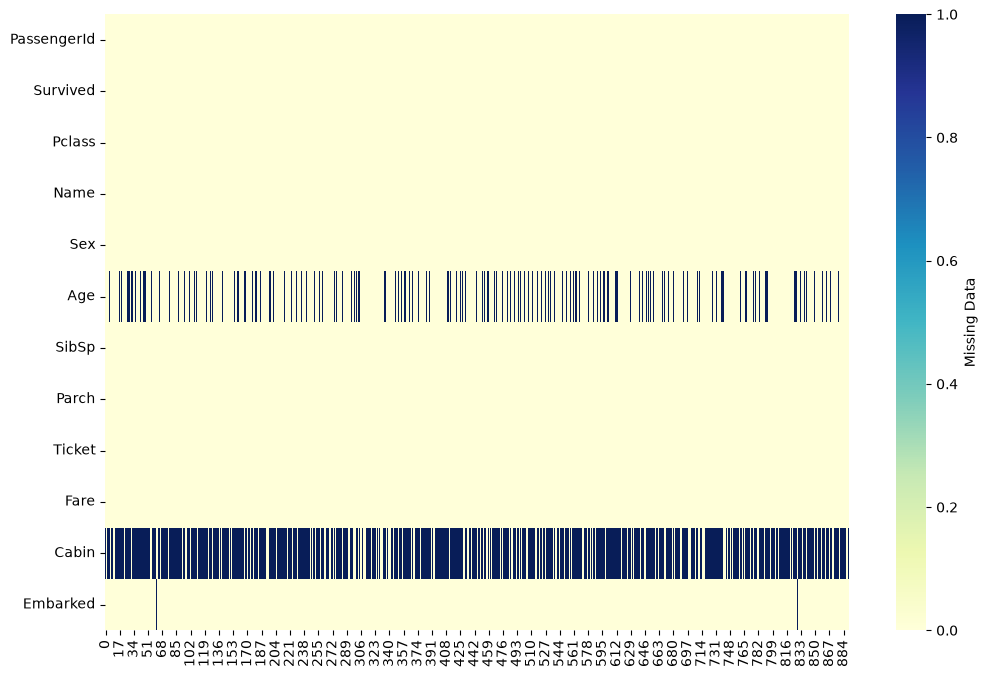

In [10]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.isna().transpose(), cmap='YlGnBu', cbar_kws={'label': 'Missing Data'}, yticklabels=True)

In [11]:
df['Ticket'].unique()

<StringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOTON/OQ 392076',
           '211536',           '112053',           '111369',
           '370376']
Length: 681, dtype: str

In [13]:
df.drop(columns=['PassengerId', 'Ticket', 'Cabin'], inplace=True)

In [14]:
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S


C:\Users\nober\AppData\Local\Temp\ipykernel_14404\1025082474.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, palette='Set1')


<Axes: xlabel='Survived', ylabel='count'>

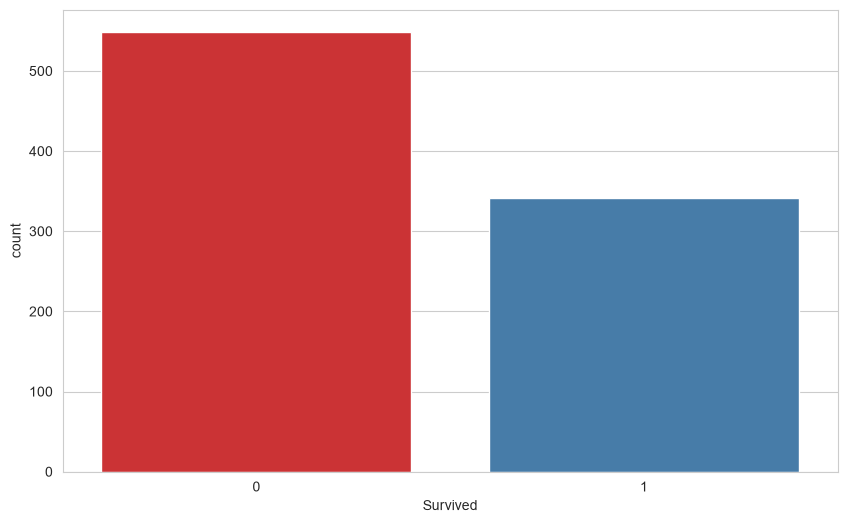

In [16]:
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.countplot(x='Survived', data=df, palette='Set1')

<Axes: xlabel='Survived', ylabel='count'>

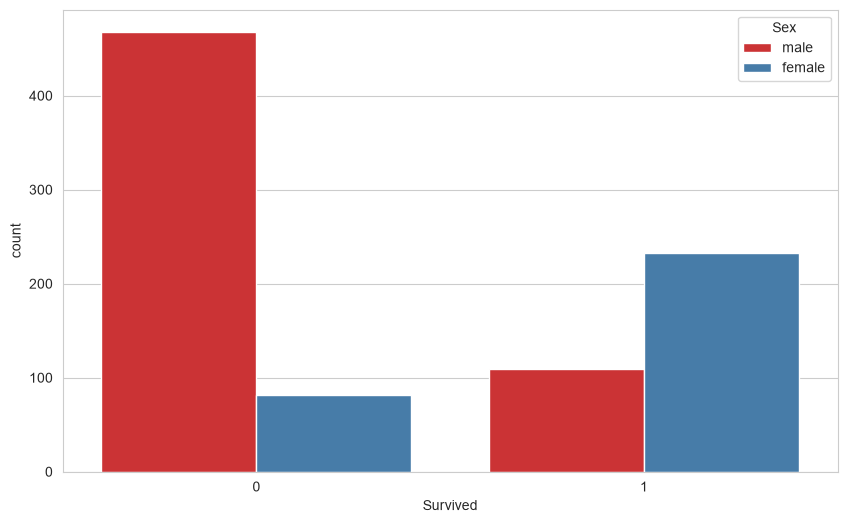

In [17]:
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Sex', data=df, palette='Set1')

<Axes: xlabel='Survived', ylabel='count'>

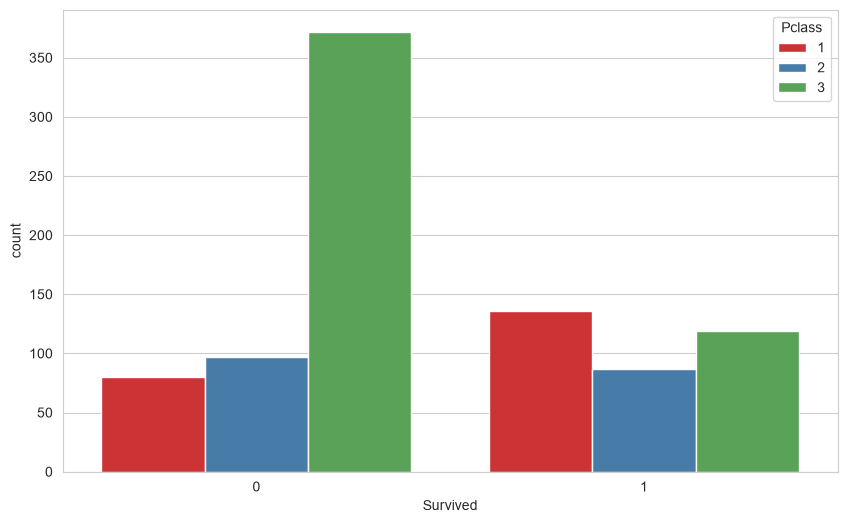

In [18]:
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.countplot(x='Survived', hue='Pclass', data=df, palette='Set1')

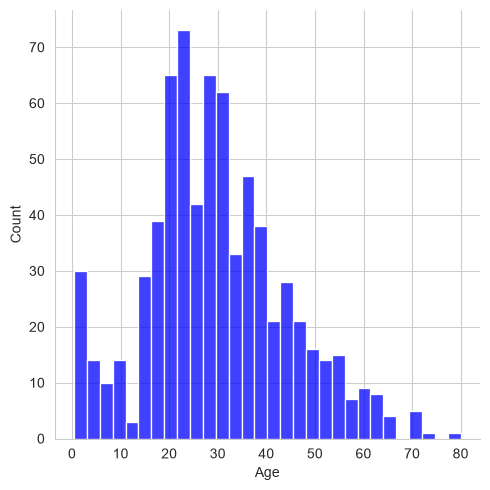

In [19]:
sns.displot(df['Age'].dropna(), kde=False, bins=30, color='blue')

Text(0.5, 1.0, 'Fare Distribution')

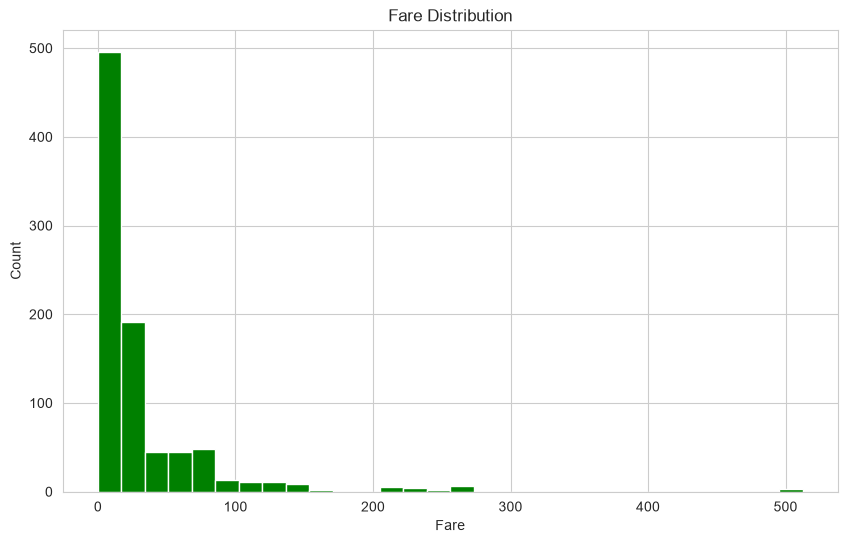

In [25]:
plt.figure(figsize=(10, 6))
ax = df['Fare'].hist(color='green', bins=30)
ax.set_xlabel('Fare')
ax.set_ylabel('Count')
ax.set_title('Fare Distribution')

<Axes: xlabel='Fare', ylabel='Count'>

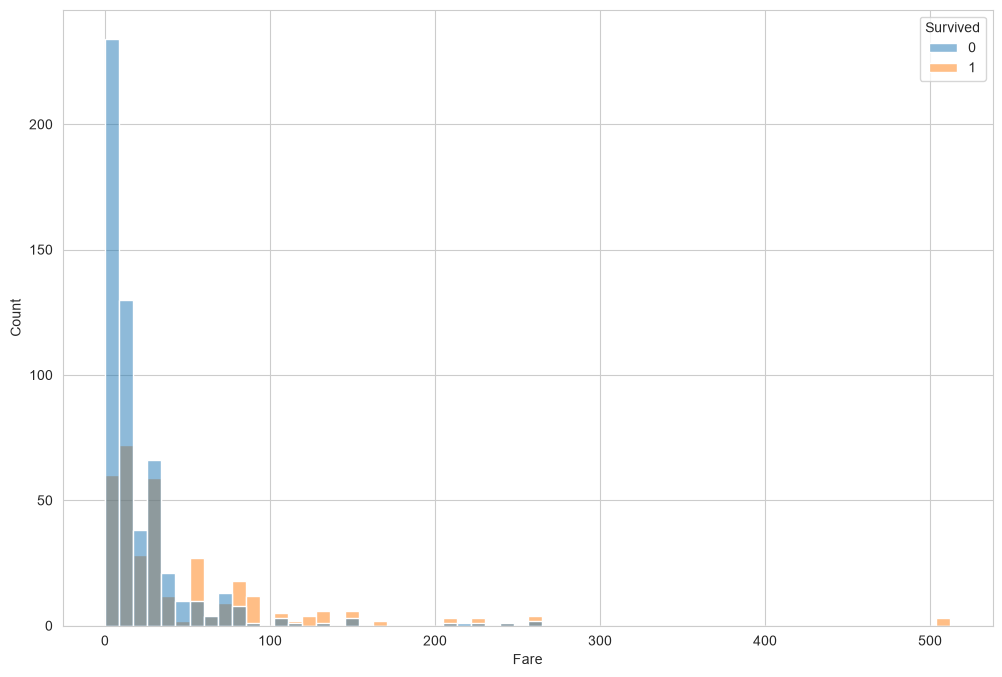

In [29]:
plt.figure(figsize=(12, 8))
sns.histplot(x='Fare', hue='Survived', data=df,)

<Axes: xlabel='Pclass', ylabel='Age'>

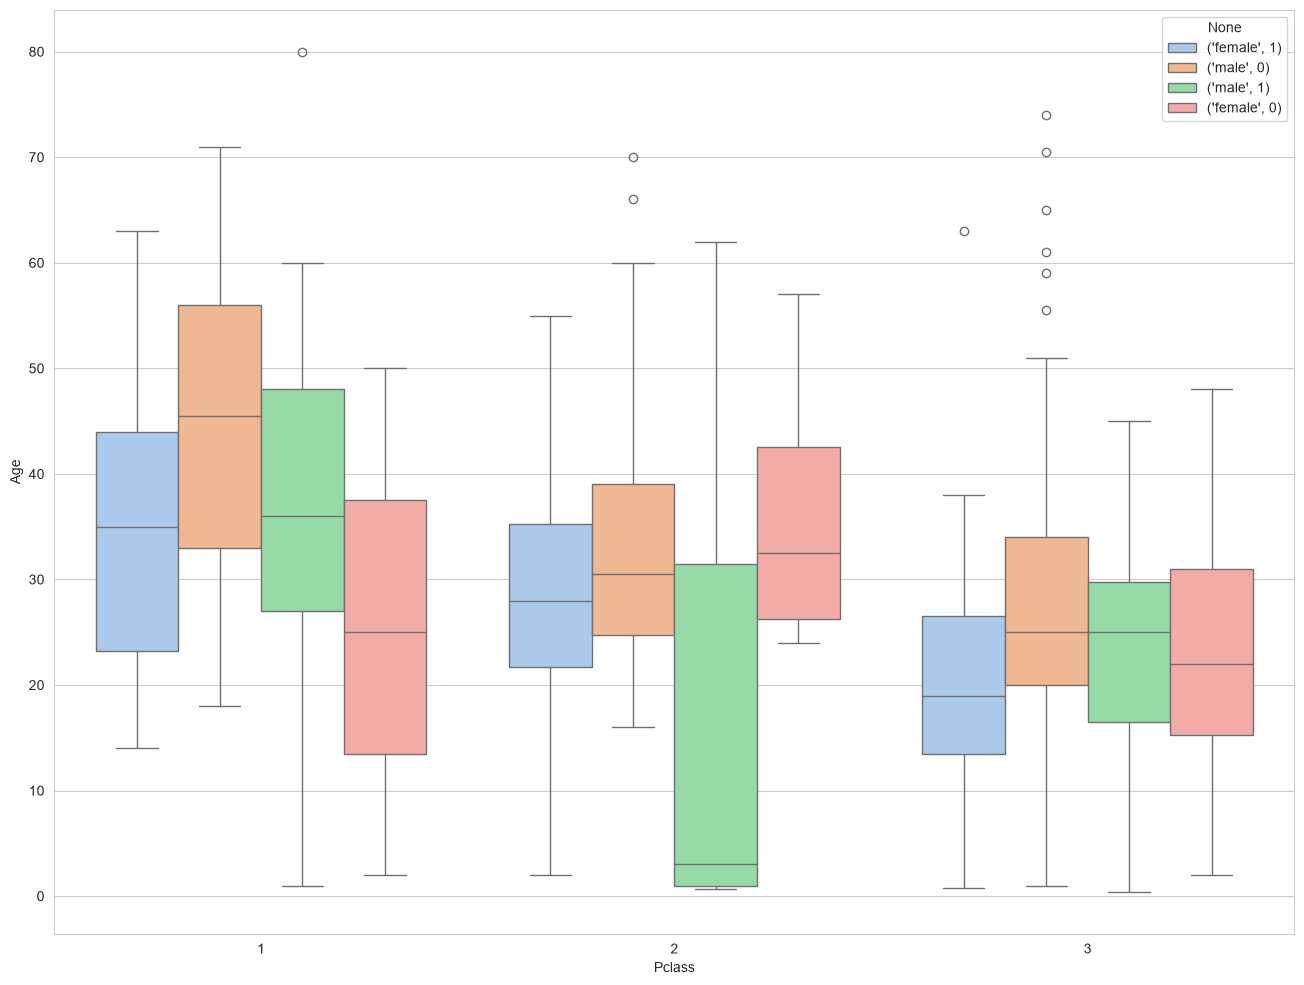

In [30]:
plt.figure(figsize=(16, 12))
sns.boxplot(x='Pclass', y='Age', hue=df[['Sex', 'Survived']].apply(tuple, axis=1), data=df, palette='pastel')

In [ ]:
age_medians = df.groupby(['Pclass', 'Survived', 'Sex'])['Age'].median()
class_sex_medians = df.groupby(['Pclass', 'Sex'])['Age'].median()

def inpute_age(cols: pd.Series) -> float:
    age = cols['Age']

    if pd.isna(age):
        pclass = int(cols['Pclass'])
        survived = int(cols['Survived'])
        gender = str(cols['Sex'])
        key = (pclass, survived, gender)

        if key in age_medians.index:
            return float(age_medians.loc[key])

        return float(class_sex_medians.loc[(pclass, gender)])

    return float(age)

df['Age'] = df[['Age', 'Pclass', 'Survived', 'Sex']].apply(inpute_age, axis=1)